# 0.1 Project brief, references and how to use this guide

This guide designs one small reinforced-concrete office building from start to finish: **analysis → slab → beam → column → pad footing**, to Eurocode 2.
Every calculation row shows the **reference**, the **formula with numbers substituted**, and the **result**.

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

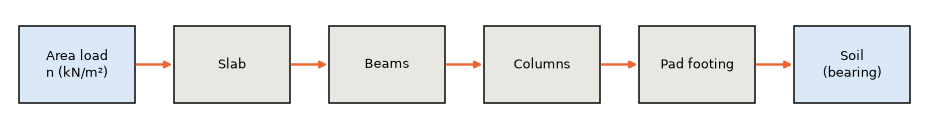

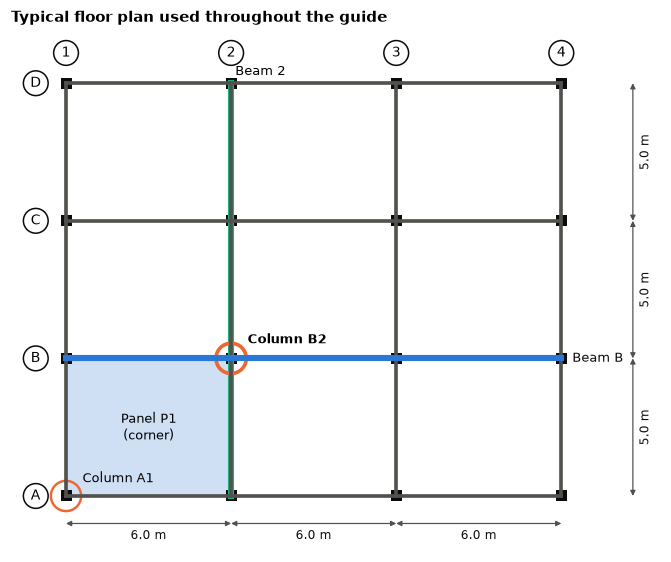

In [2]:
P.sketch_load_path()
P.sketch_plan()

## Project inputs

These values are **inputs, not code values**. On a real job they come from the client, the architect, the loading code or the ground investigation.
They live in one place, `ec2/project.py` (`BRIEF`). Change them there, re-run the notebooks, and the whole load path updates.

### Input guide: `BRIEF`, in `ec2/project.py`

`BRIEF` holds the building. After editing it, restart the kernel and run all cells.

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `ndp` | National values | | `UK` or `EN` without quotes (import `EN` first) |
| `bays_x`, `bays_y` | Number of bays; display only, three each way is built in | | leave at 3 |
| `lx_bay`, `ly_bay` | Bay sizes | m | `lx_bay` ≥ `ly_bay`, ratio at most 2 |
| `levels` | Suspended levels above the ground-storey column | | whole number |
| `storey` | Floor to floor height | m | > 0 |
| `h_slab` | Slab thickness | mm | less than the beam depth |
| `beam` | `(width, overall depth)` | mm | |
| `col` | `(width, depth)` | mm | square |
| `finishes`, `qk`, `partitions` | Characteristic area loads | kN/m² | partitions 0.5, 0.8 or 1.2 (EN 1991-1-1 6.3.1.2(8)) |
| `category` | Use category; sets ψ₂ only, not `qk` | | `"A"` to `"E"` |
| `facade` | Wall on every edge beam, characteristic | kN/m | ≥ 0 |
| `fck`, `fyk`, `dg` | Concrete, steel, largest aggregate | N/mm², mm | fck 12 to 50; fyk 400 to 600 |
| `exposure`, `exposure_ground` | Exposure of superstructure and footings | | `"X0"`, `"XC1"` to `"XC4"`, `"XD1"` to `"XD3"`, `"XS1"` to `"XS3"` |
| `fire` | Fire rating | minutes | 30, 60 or 90 |
| `bearing` | Presumed gross bearing pressure | kN/m² | from the ground investigation |
| `overburden` | Backfill and ground slab over the pad | kN/m² | ≥ 0 |
| `RH`, `t0` | Humidity; concrete age at loading | %, days | for creep |

**In every notebook:** numbers have no quotes, text has quotes, decimals use a point. Change the values, not the names.

| Message | Usual cause |
|:--|:--|
| `NameError` | A name is misspelled or in lower case, or the input cell was not run |
| `KeyError` | An exposure, fire rating, ground or bar-location name that is not listed |
| `TypeError` | A number in quotes, or a load outside its list |
| `AttributeError` | `UVL` or `Moment` used in a continuous beam |
| `ValueError` | A value outside the limits, or a section that is too small |
| ❌ in the summary | The inputs are valid but the design does not work: change the size or bars |

b = BRIEF
table([["National parameters", b["ndp"]["name"], "chosen for the project (EC2 allows national choice)"],
       ["Grid", f'{b["bays_x"]} × {b["lx_bay"]} m by {b["bays_y"]} × {b["ly_bay"]} m', "architect"],
       ["Suspended levels on a ground-storey column", b["levels"], "architect: 2 floors + accessible roof (EN 1991-1-1 Table 6.9, category I)"],
       ["Storey height", f'{b["storey"]} m', "architect"],
       ["Stability", "braced: shear walls/core resist all lateral load", "structural scheme"],
       ["Slab / beams / columns", f'{b["h_slab"]} mm / {b["beam"][0]}×{b["beam"][1]} / {b["col"][0]}×{b["col"][1]} mm', "trial sizes, verified in the notebooks"],
       ["Finishes, ceiling, services", f'{b["finishes"]} kN/m²', "client / architect"],
       ["Imposed load, category B", f'{b["qk"]} kN/m²', "EN 1991-1-1 Table 6.2, recommended value"],
       ["Movable partitions", f'{b["partitions"]} kN/m²', "EN 1991-1-1 6.3.1.2(8), 1.0 to 2.0 kN/m"],
       ["Façade line load", f'{b["facade"]} kN/m', "architect"],
       ["Concrete / steel", f'C{b["fck"]}/37, fyk = {b["fyk"]} N/mm²', "EC2 Table 3.1, 3.2.2"],
       ["Exposure, superstructure / footing", f'{b["exposure"]} / {b["exposure_ground"]}', "EC2 Table 4.1"],
       ["Fire resistance", f'R {b["fire"]}', "fire strategy / building regulations"],
       ["Presumed bearing pressure (gross)", f'{b["bearing"]} kN/m²', "ground investigation; EN 1997-1 6.5.2.4"],
       ["Overburden on the pad", f'{b["overburden"]} kN/m²', "project"]],
      ["Input", "Value", "Source"])

## Design workflow

| Step | What is done | Where |
|:--|:--|:--|
| 1 | Geometry, materials, exposure, fire, actions | 0.1, 2.1 |
| 2 | Structural analysis: bending moments and shears | 1.1 to 1.3 |
| 3 | Section theory: bending, shear, serviceability, bond | 2.1 to 2.4 |
| 4 | Slabs: ULS bending, shear, deflection, cracking, detailing | 3.1 to 3.3 |
| 5 | Slab load to beams, then beam design | 4.1 to 4.3 |
| 6 | Beam reactions to columns, then column design | 5.1 to 5.4 |
| 7 | Column load to the pad footing | 6.1, 6.2 |

## References

| Short name in the sheets | Document | How it was used here |
|:--|:--|:--|
| **EC2** | EN 1992-1-1:2004 + corrigenda (first-generation Eurocode 2) | Clauses, expressions and tables read from the standard |
| **NA** | UK National Annex to EN 1992-1-1, incl. National Amendment No. 1 (2009) | Nationally Determined Parameters read from the annex |
| **EN 1992-1-2** | Structural fire design | Tables 5.2a, 5.5, 5.6, 5.8 |
| **EN 1990** | Basis of structural design, and its UK NA | Combinations, ψ factors |
| **EN 1991-1-1** | Densities, self-weight, imposed loads | Tables 6.2, A.1 |
| **EN 1997-1** | Geotechnical design | 6.5.2.4 (presumed bearing resistance) |
| **BS 8110-1** | BS 8110-1:1997 (amendments 1 and 2), *Structural use of concrete*, withdrawn by BSI, superseded by EC2 | Only where EC2 gives no rule: Tables 3.12 to 3.15 (slab coefficients), 3.5.3.5 (strips, corner steel), 3.2.1.2.5 (column moments), 3.4.4.4 (z ≤ 0.95d), 3.8.3.2 c) (slender columns). Loads are always EN 1990 |
| **JRC EUR 26566** | *Eurocode 2: Background & Applications. Design of Concrete Buildings. Worked examples* (JRC, 2014) | Method references and benchmarks in `tests/` |
| **NPTEL L12, L13, L18** | *Structural Analysis II*, IIT Kharagpur (course 105105109), Lessons 12, 13, 18 | Three-moment equation; moment distribution |
| **Textbook** | Mosley, Bungey & Hulse, *Reinforced Concrete Design to Eurocode 2*; Hibbeler, *Structural Analysis* | Background reading by topic only. Page and equation numbers were not checked, so none are quoted |

> **Scope and limits.** Covers fck ≤ 50 N/mm² (50 MPa), ribbed B500 bars, braced frames, uniformly loaded solid slabs and rectangular pads without punching reinforcement.
> Not covered: lateral-load analysis, robustness ties (EC2 9.10, PD 6687), seismic design, torsion, flat slabs, full geotechnical verification, detailed crack-width calculation.
> The UK NA sends cover and concrete quality to **BS 8500-1**, which was not available when this guide was written. The sheets use the EC2 Table 4.4N recommended values and flag that step.
> Any calculation used for construction must be checked by a competent engineer.

## Printing the sheets without code

```bash
source .venv/bin/activate                         # once per terminal; Windows: .venv\Scripts\Activate.ps1
python tools/export_sheets.py            # all notebooks -> calc_sheets/*.pdf, no code
python tools/export_sheets.py 04_Beam    # only notebooks whose path contains this text
```

## Sign convention and units

- Sagging moment positive, drawn below the axis. Loads act downward.
- Forces in kN, changed to N inside resistance formulas. The 10³ and 10⁶ factors are shown in each formula.
- Stress in N/mm² and pressure in kN/m². The sheets print the MPa or Pa value beside each one.
- MPa and Pa measure stress (force ÷ area), not force.

| Quantity | Unit used | Conversion |
|:--|:--|:--|
| Force | kN, N | 1 kN = 1000 N |
| Moment | kN·m, N·mm | 1 kN·m = 10⁶ N·mm |
| Stress, strength | N/mm² | 1 N/mm² = 1 MPa = 10⁶ Pa |
| Pressure, area load | kN/m² | 1 kN/m² = 1 kPa = 1000 Pa = 0.001 MPa |
| Elastic modulus (tables) | kN/mm² | 1 kN/mm² = 1 GPa = 1000 MPa |

EC2 states its formulas in MPa. The numbers are the same in N/mm².
- "H" = ribbed high-yield bar, e.g. H16 @ 200.